In [1]:
import os
import glob
import librosa
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, Dropout, LSTM
from keras.layers import TimeDistributed 
import tkinter as tk
from tkinter import filedialog
from pydub import AudioSegment
from pydub.playback import play
import sounddevice as sd
from PIL import Image, ImageTk 
from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

C:\Users\Dell\AppData\Roaming\Python\Python311\site-packages\pydub\utils.py:170: RuntimeWarning: Couldn't find ffmpeg or avconv - defaulting to ffmpeg, but may not work
  warn("Couldn't find ffmpeg or avconv - defaulting to ffmpeg, but may not work", RuntimeWarning)


In [2]:
def extract_features(file_path):
    audio, sr = librosa.load(file_path, res_type='kaiser_fast')
    features = np.mean(librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=13).T, axis=0)
    return features

data = []
labels = []
for folder_name in os.listdir('C:/Users/Dell/Downloads/SER/SER Dataset/TESS Toronto emotional speech set data/'):
    folder_path = os.path.join('C:/Users/Dell/Downloads/SER/SER Dataset/TESS Toronto emotional speech set data/', folder_name)
    for file_path in glob.glob(os.path.join(folder_path, '*.wav')):
        print(file_path)
        features = extract_features(file_path)
        data.append(features)
        labels.append(folder_name)

C:/Users/Dell/Downloads/SER/SER Dataset/TESS Toronto emotional speech set data/OAF_Pleasant_surprise\OAF_back_ps.wav
C:/Users/Dell/Downloads/SER/SER Dataset/TESS Toronto emotional speech set data/OAF_Pleasant_surprise\OAF_bar_ps.wav
C:/Users/Dell/Downloads/SER/SER Dataset/TESS Toronto emotional speech set data/OAF_Pleasant_surprise\OAF_base_ps.wav
C:/Users/Dell/Downloads/SER/SER Dataset/TESS Toronto emotional speech set data/OAF_Pleasant_surprise\OAF_bath_ps.wav
C:/Users/Dell/Downloads/SER/SER Dataset/TESS Toronto emotional speech set data/OAF_Pleasant_surprise\OAF_bean_ps.wav
C:/Users/Dell/Downloads/SER/SER Dataset/TESS Toronto emotional speech set data/OAF_Pleasant_surprise\OAF_beg_ps.wav
C:/Users/Dell/Downloads/SER/SER Dataset/TESS Toronto emotional speech set data/OAF_Pleasant_surprise\OAF_bite_ps.wav
C:/Users/Dell/Downloads/SER/SER Dataset/TESS Toronto emotional speech set data/OAF_Pleasant_surprise\OAF_boat_ps.wav
C:/Users/Dell/Downloads/SER/SER Dataset/TESS Toronto emotional spe

In [3]:
# Encode class labels using LabelEncoder
label_encoder = LabelEncoder()
labels_encoded = label_encoder.fit_transform(labels)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(data, labels_encoded, test_size=0.2, random_state=42)

# Expand dimensions to match the expected input shape for LSTM
X_train = np.array(X_train)[:, np.newaxis, :]
X_test = np.array(X_test)[:, np.newaxis, :]

# Get the number of training and testing samples
num_training_samples = X_train.shape[0]
num_testing_samples = X_test.shape[0]

# Build and compile the model
model = Sequential()
model.add(TimeDistributed(Dense(256, activation='relu'), input_shape=(1, X_train.shape[2])))
model.add(Dropout(0.5))
model.add(LSTM(128))
model.add(Dropout(0.5))
model.add(Dense(len(label_encoder.classes_), activation='softmax'))
model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# Train the model
history = model.fit(X_train, y_train, epochs=75, batch_size=32, validation_data=(X_test, y_test))

# Evaluate the model on the test set
loss, accuracy = model.evaluate(X_test, y_test)
print('Test loss:', loss)
print('Test accuracy:', accuracy)

# Evaluate the model on the test set
loss_t, accuracy_t = model.evaluate(X_train, y_train)
print('Training loss:', loss_t)
print('Training accuracy:', accuracy_t)



Epoch 1/75


45/45 [==============================] - 5s 24ms/step - loss: 2.3339 - accuracy: 0.1090 - val_loss: 2.1954 - val_accuracy: 0.1000
Epoch 2/75
45/45 [==============================] - 0s 6ms/step - loss: 2.2662 - accuracy: 0.1243 - val_loss: 2.1844 - val_accuracy: 0.1333
Epoch 3/75
45/45 [==============================] - 0s 6ms/step - loss: 2.2170 - accuracy: 0.1361 - val_loss: 2.1939 - val_accuracy: 0.0528
Epoch 4/75
45/45 [==============================] - 0s 5ms/step - loss: 2.1969 - accuracy: 0.1389 - val_loss: 2.1287 - val_accuracy: 0.1361
Epoch 5/75
45/45 [==============================] - 0s 6ms/step - loss: 2.1723 - accuracy: 0.1514 - val_loss: 2.1224 - val_accuracy: 0.2472
Epoch 6/75
45/45 [==============================] - 0s 6ms/step - loss: 2.1607 - accuracy: 0.1535 - val_loss: 2.0634 - val_accuracy: 0.3750
Epoch 7/75
45/45 [==============================] - 0s 5ms/step - loss: 2.0882 - accuracy: 0.2090 - val_loss: 1.9137 - val_accuracy: 0.3556
Epoch 8/75
45/4

In [4]:
# Make predictions on the test set
y_pred = np.argmax(model.predict(X_test), axis=1)

# Decode integer labels back to original class labels
y_test_original = label_encoder.inverse_transform(y_test)
y_pred_original = label_encoder.inverse_transform(y_pred)

# Print classification report
print("Classification Report:")
print(classification_report(y_test_original, y_pred_original))

# Print the number of training and testing samples
print(f'Number of training samples: {num_training_samples}')
print(f'Number of testing samples: {num_testing_samples}')

12/12 [==============================] - 1s 2ms/step
Classification Report:
                        precision    recall  f1-score   support

 OAF_Pleasant_surprise       1.00      1.00      1.00        32
               OAF_Sad       1.00      1.00      1.00        47
             YAF_angry       0.92      1.00      0.96        48
           YAF_disgust       0.97      1.00      0.99        37
              YAF_fear       0.97      0.94      0.96        36
             YAF_happy       1.00      0.91      0.95        32
           YAF_neutral       0.96      1.00      0.98        46
YAF_pleasant_surprised       0.97      0.90      0.94        41
               YAF_sad       1.00      1.00      1.00        41

              accuracy                           0.97       360
             macro avg       0.98      0.97      0.97       360
          weighted avg       0.98      0.97      0.97       360

Number of training samples: 1440
Number of testing samples: 360


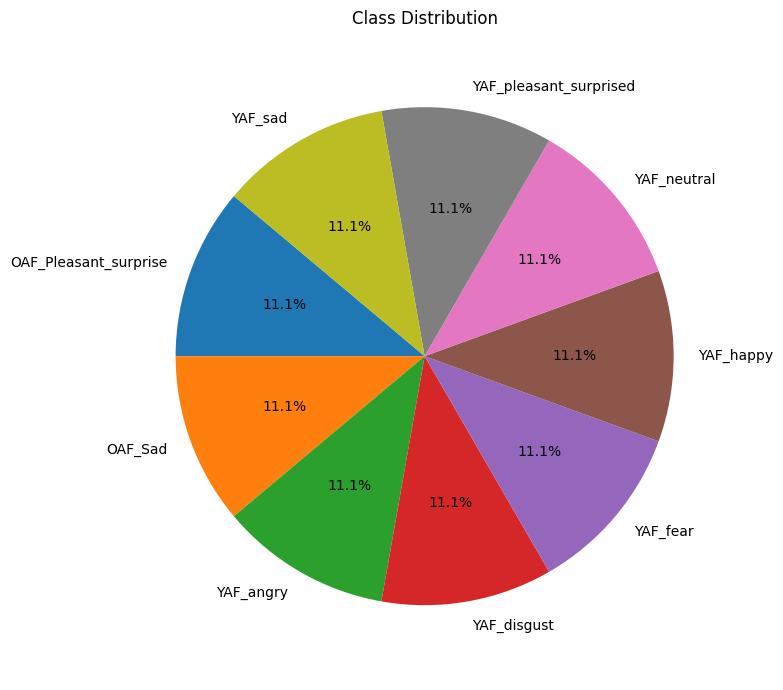

In [5]:
# Plot a pie chart of class distribution with increased size
plt.subplot(1, 3, 3)
class_counts = np.bincount(labels_encoded)
class_labels = label_encoder.classes_
plt.pie(class_counts, labels=class_labels, autopct='%1.1f%%', startangle=140)
plt.title('Class Distribution')

# Increase the size of the pie chart
plt.gcf().set_size_inches(20, 7)

# Ensure the pie chart maintains a circular shape
plt.axis('equal')

plt.tight_layout()
plt.show()

12/12 [==============================] - 0s 2ms/step
Confusion Matrix:
[[32  0  0  0  0  0  0  0  0]
 [ 0 47  0  0  0  0  0  0  0]
 [ 0  0 48  0  0  0  0  0  0]
 [ 0  0  0 37  0  0  0  0  0]
 [ 0  0  0  0 34  0  1  1  0]
 [ 0  0  2  0  0 29  1  0  0]
 [ 0  0  0  0  0  0 46  0  0]
 [ 0  0  2  1  1  0  0 37  0]
 [ 0  0  0  0  0  0  0  0 41]]


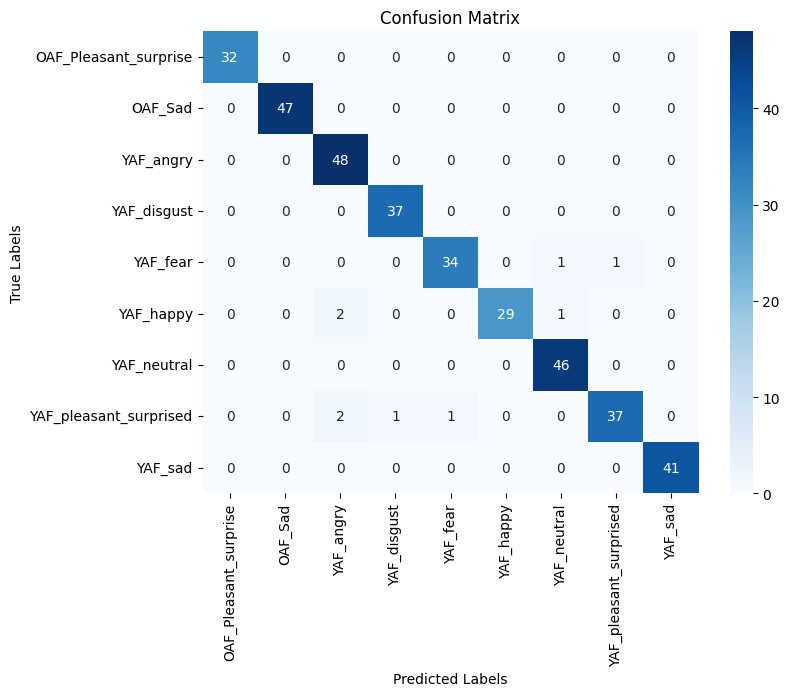

In [6]:
# Make predictions on the test set
y_pred = np.argmax(model.predict(X_test), axis=1)

# Decode integer labels back to original class labels
y_test_original = label_encoder.inverse_transform(y_test)
y_pred_original = label_encoder.inverse_transform(y_pred)

# Generate and print the confusion matrix
conf_matrix = confusion_matrix(y_test_original, y_pred_original)
print("Confusion Matrix:")
print(conf_matrix)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

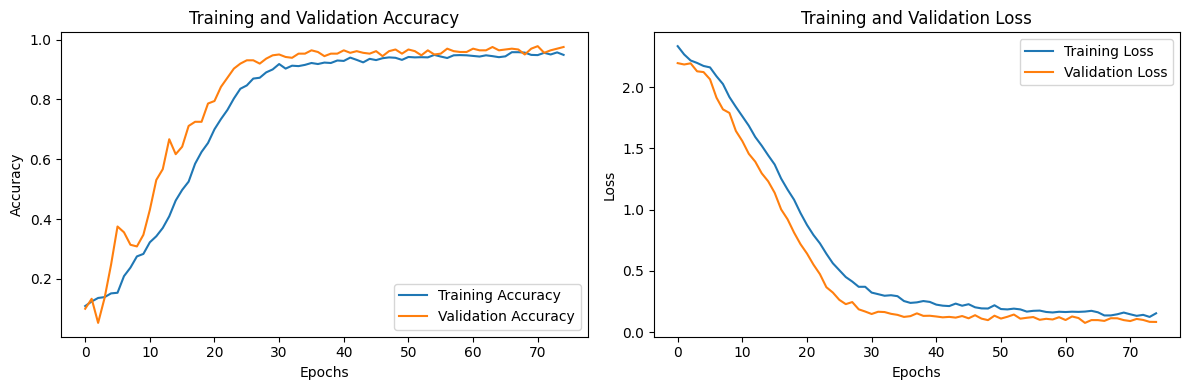

In [7]:
# Plot training and validation accuracy values
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()

# Plot training and validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [8]:
def predict_emotion(audio_file):
    features = extract_features(audio_file)
    features = features[np.newaxis, np.newaxis, :]  
    print("Features shape:", features.shape)
    print("Features:", features)

    predicted_probabilities = model.predict(features)
    print("Predicted probabilities shape:", predicted_probabilities.shape)
    print("Predicted probabilities:", predicted_probabilities)

    predicted_label_index = np.argmax(predicted_probabilities)
    print("Predicted label index:", predicted_label_index)

    predicted_emotion = label_encoder.classes_[predicted_label_index]
    print("Predicted emotion:", predicted_emotion)


    # Emotion mapping for TESS dataset
    emotion_mapping = {
        'Actor_Disguist': 'DISGUIST',
        'Actor_Sad': 'SAD',
        'Actor_Happy': 'HAPPY',
        'Actor_Angry': 'ANGRY',
        'Actor_Neutral': 'NEUTRAL',
        'Actor_Fear': 'FEAR',
    }


    recognizable_emotion = emotion_mapping.get(predicted_emotion)
    return recognizable_emotion

In [9]:
class EmotionApp:
    def __init__(self, root):
        self.root = root
        self.root.title("Emotion prediction of speech")
        self.root.configure(bg='white')
       
        self.emotion_to_emoji = {
            "HAPPY": "C:/Users/Dell/Downloads/SER/happy.png",
            "SAD": "C:/Users/Dell/Downloads/SER/sad.png",
            "ANGRY": "C:/Users/Dell/Downloads/SER/angry.png",
            "NEUTRAL": "C:/Users/Dell/Downloads/SER/neutral.png",
            "FEAR": "C:/Users/Dell/Downloads/SER/fear.png",
            "DISGUST": "C:/Users/Dell/Downloads/SER/disgusted.png"
        }
        
        self.emoji_image = None  
        self.prediction_history = []  
        
        self.show_home_page()
        
    def show_home_page(self):
        self.clear_window()
        
        label = tk.Label(self.root, text=" Welcome to Speech Prediction ", font=('Helvetica bold', 16),bg='white')
        label.pack(pady=20)
        
        button = tk.Button(self.root, text="Audio Prediction", command=self.show_audio_page, bg='orange')
        button.pack()
        
        button_history = tk.Button(self.root, text="Prediction History", command=self.show_history_page, bg='yellow')
        button_history.pack(pady=90)
        
    def show_audio_page(self):
        self.clear_window()
        
        canvas = tk.Canvas(self.root, width=300, height=300, bg='white')
        canvas.pack()
        
        label1 = tk.Label(self.root, text='Emotion of speech', font=('Helvetica bold', 15),bg='white')
        canvas.create_window(150, 50, window=label1)
        
        def upload_audio():
            file_path = filedialog.askopenfilename(filetypes=[("Audio Files", "*.wav")])
            if file_path:
                predicted_emotion = predict_emotion(file_path)
                label2.config(text=predicted_emotion)
                
                self.prediction_history.append((os.path.basename(file_path), predicted_emotion))
                
                emoji_image_path = self.emotion_to_emoji.get(predicted_emotion)
                if emoji_image_path:
                    emoji_image = Image.open(emoji_image_path)
                    emoji_image = emoji_image.resize((50, 50), Image.ANTIALIAS)
                    self.emoji_image = ImageTk.PhotoImage(emoji_image)
                    emoji_label.config(image=self.emoji_image)
                
        button1 = tk.Button(self.root, text='Upload Audio', command=upload_audio, bg='lightgreen')
        canvas.create_window(150, 100, window=button1)
        
        label2 = tk.Label(self.root, text='Predicted emotion will be displayed here')
        canvas.create_window(150, 130, window=label2)
        
        emoji_label = tk.Label(self.root, image=None)
        canvas.create_window(150, 180, window=emoji_label)
        
        back_button = tk.Button(self.root, text="Back to Home", command=self.show_home_page)
        canvas.create_window(150, 250, window=back_button)
        
    def show_history_page(self):
        self.clear_window()
        
        canvas = tk.Canvas(self.root, width=300, height=300, bg='white')
        canvas.pack()
        
        label = tk.Label(self.root, text="Prediction History", font=('Helvetica bold', 16),bg='white')
        canvas.create_window(150, 50, window=label)
        
        if self.prediction_history:
            for index, (file_name, predicted_emotion) in enumerate(self.prediction_history, start=1):
                history_text = f"{index}. File: {file_name}, Emotion: {predicted_emotion}"
                history_label = tk.Label(self.root, text=history_text)
                canvas.create_window(150, 50 + index * 30, window=history_label)
        else:
            no_history_label = tk.Label(self.root, text="No prediction history available.")
            canvas.create_window(150, 150, window=no_history_label)
        
        back_button = tk.Button(self.root, text="Back to Home", command=self.show_home_page)
        canvas.create_window(150, 250, window=back_button)
        
        
    def clear_window(self):
        for widget in self.root.winfo_children():
            widget.destroy()

if __name__ == "__main__":
    root = tk.Tk()
    app = EmotionApp(root)
    root.mainloop()